https://docs.fastf1.dev/gen_modules/examples_gallery/index.html
this ipynb is all about replicating the plots, but in Plotly instead of Matplotlib

# Summary:
* 1. Plot Styling
    * 1.1 Driver specific plot styling
    * 1.2 Draw a track map with numbered corners
* 2. Lap Time Analysis
    * 2.1 
    * 2.2 
* 3. Strategy and Results Analysis
    * 3.1 

# 1. Plot Styling

### 1.1 Driver specific plot styling

In [55]:
from matplotlib import pyplot as plt
import numpy as np
import fastf1
from fastf1 import plotting

# Enable Matplotlib patches for plotting timedelta values and load
# FastF1's dark color scheme
fastf1.plotting.setup_mpl(mpl_timedelta_support=True, color_scheme='fastf1')

race = fastf1.get_session(2023, "Azerbaijan", 'R')
race.load()

core           INFO 	Loading data for Azerbaijan Grand Prix - Race [v3.8.3]
req            INFO 	Using cached data for session_info
req            INFO 	Using cached data for driver_info
req            INFO 	Using cached data for session_status_data
req            INFO 	Using cached data for lap_count
req            INFO 	Using cached data for track_status_data
req            INFO 	Using cached data for _extended_timing_data
req            INFO 	Using cached data for timing_app_data
core           INFO 	Processing timing data...
req            INFO 	Using cached data for car_data
req            INFO 	Using cached data for position_data
req            INFO 	Using cached data for weather_data
req            INFO 	Using cached data for race_control_messages
core           INFO 	Finished loading data for 20 drivers: ['11', '1', '16', '14', '55', '44', '18', '63', '4', '22', '81', '23', '20', '10', '31', '2', '27', '77', '24', '21']


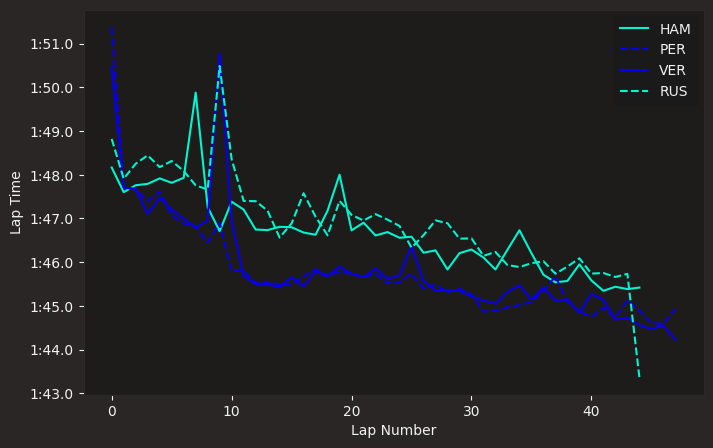

In [56]:
fig, ax = plt.subplots(figsize=(8, 5))

for driver in ('HAM', 'PER', 'VER', 'RUS'):
    laps = race.laps.pick_drivers(driver).pick_quicklaps().reset_index()
    style = plotting.get_driver_style(identifier=driver,
                                      style=['color', 'linestyle'],
                                      session=race)
    ax.plot(laps['LapTime'], **style, label=driver)

# add axis labels and a legend
ax.set_xlabel("Lap Number")
ax.set_ylabel("Lap Time")
ax.legend()

In [57]:
#conveerting from matplotlib to plotly
from plotly.tools import mpl_to_plotly
import plotly.graph_objects as go

plotly_fig = mpl_to_plotly(fig)
import plotly.io as pio
pio.show(plotly_fig)

/Users/aksha/Documents/C/CoDeS/AI_Engineer/FastF1/venv/lib/python3.12/site-packages/plotly/matplotlylib/renderer.py:556: UserWarning: I found a path object that I don't think is part of a bar chart. Ignoring.
  warnings.warn(


In [60]:
# plotly
line_style_map = {
    'solid': 'solid',
    'dashed': 'dash',
    'dashdot': 'dashdot',
    'dotted': 'dot'
}

drivers = ('HAM', 'PER', 'VER', 'RUS')
event_name = race.event.get('EventName', race.event.get('Location', ''))
event_year = race.event['EventDate'].year if 'EventDate' in race.event else getattr(race, 'year', '')

title = f"{event_year} {event_name}: {' / '.join(drivers)} Lap Times"

fig = go.Figure()

for driver in drivers:
    laps = race.laps.pick_drivers(driver).pick_quicklaps().reset_index()
    mpl_style = plotting.get_driver_style(identifier=driver,
                                          style=['color', 'linestyle'],
                                          session=race)

    fig.add_trace(go.Scatter(
        x=laps['LapNumber'],
        y=laps['LapTime'].dt.total_seconds(),
        mode='lines',
        name=driver,
        line=dict(
            color=mpl_style.get('color'),
            dash=line_style_map.get(mpl_style.get('linestyle', 'solid'), 'solid'),
            width=2
        )
    ))

fig.update_layout(
    title=title,
    xaxis_title='Lap Number',
    yaxis_title='Lap Time (s)',
    template='plotly_dark'
)

fig.show()

In [61]:
# example checkbox-style input from swagger
selected_drivers = ['HAM', 'PER', 'VER', 'RUS']  # replace with the list sent by swagger

fig = go.Figure()

for driver in drivers:
    laps = race.laps.pick_drivers(driver).pick_quicklaps().reset_index()
    mpl_style = plotting.get_driver_style(identifier=driver,
                                          style=['color', 'linestyle'],
                                          session=race)

    fig.add_trace(go.Scatter(
        x=laps['LapNumber'],
        y=laps['LapTime'].dt.total_seconds(),
        mode='lines',
        name=driver,
        visible=driver in selected_drivers,
        line=dict(
            color=mpl_style.get('color'),
            dash=line_style_map.get(mpl_style.get('linestyle', 'solid'), 'solid'),
            width=2
        )
    ))

fig.update_layout(
    title=title,
    xaxis_title='Lap Number',
    yaxis_title='Lap Time (s)',
    template='plotly_dark',
    legend=dict(itemclick='toggle', itemdoubleclick='toggleothers')
)

fig.show()

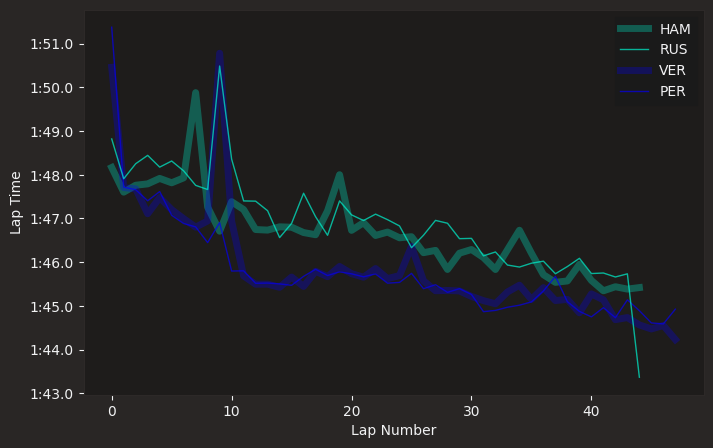

In [5]:
# sample code for custom styling
my_styles = [
    # style for each first driver
    {'color': 'auto', 'linestyle': 'solid', 'linewidth': 5, 'alpha': 0.3},
    # style for each second driver
    {'color': 'auto', 'linestyle': 'solid', 'linewidth': 1, 'alpha': 0.7}
]

fig, ax = plt.subplots(figsize=(8, 5))

for driver in ('HAM', 'PER', 'VER', 'RUS'):
    laps = race.laps.pick_drivers(driver).pick_quicklaps().reset_index()

    # here, we now use ``style=my_style`` to use the custom styling
    style = plotting.get_driver_style(identifier=driver,
                                      style=my_styles,
                                      session=race)

    ax.plot(laps['LapTime'], **style, label=driver)

# add axis labels and a legend
ax.set_xlabel("Lap Number")
ax.set_ylabel("Lap Time")
plotting.add_sorted_driver_legend(ax, race)
plt.show()

### 1.2 Draw a track map with numbered corners

In [33]:
session = fastf1.get_session(2023, 'Silverstone', 'Q')
session.load()

lap = session.laps.pick_fastest()
pos = lap.get_pos_data()

circuit_info = session.get_circuit_info()

core           INFO 	Loading data for British Grand Prix - Qualifying [v3.8.3]
req            INFO 	Using cached data for session_info
req            INFO 	Using cached data for driver_info


req            INFO 	Using cached data for session_status_data
req            INFO 	Using cached data for track_status_data
req            INFO 	Using cached data for _extended_timing_data
req            INFO 	Using cached data for timing_app_data
core           INFO 	Processing timing data...
req            INFO 	Using cached data for car_data
req            INFO 	Using cached data for position_data
req            INFO 	Using cached data for weather_data
req            INFO 	Using cached data for race_control_messages
core           INFO 	Finished loading data for 20 drivers: ['1', '4', '81', '16', '55', '63', '44', '23', '14', '10', '27', '18', '31', '2', '77', '11', '22', '24', '21', '20']


In [34]:
def rotate(xy, *, angle):
    rot_mat = np.array([[np.cos(angle), np.sin(angle)],
                        [-np.sin(angle), np.cos(angle)]])
    return np.matmul(xy, rot_mat)

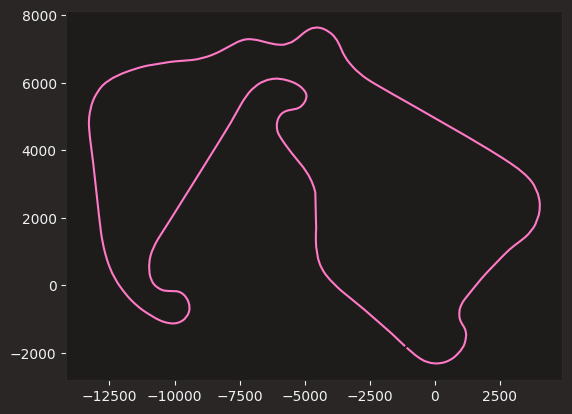

In [35]:
# Get an array of shape [n, 2] where n is the number of points and the second
# axis is x and y.
track = pos.loc[:, ('X', 'Y')].to_numpy()

# Convert the rotation angle from degrees to radian.
track_angle = circuit_info.rotation / 180 * np.pi

# Rotate and plot the track map.
rotated_track = rotate(track, angle=track_angle)
plt.plot(rotated_track[:, 0], rotated_track[:, 1])

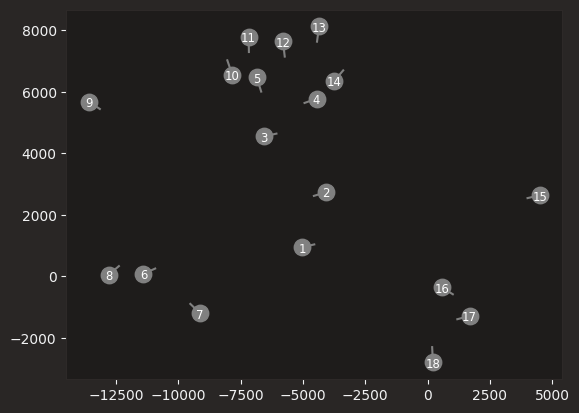

In [38]:
for _, corner in circuit_info.corners.iterrows():
    # Create label (e.g., "1", "8a")
    txt = f"{corner['Number']}{corner['Letter']}"
    
    # Convert corner angle to radians and rotate offset
    offset_angle = corner['Angle'] / 180 * np.pi
    offset_x, offset_y = rotate(offset_vector, angle=offset_angle)
    
    # Calculate text position and rotate it to match the track map
    text_x, text_y = rotate([corner['X'] + offset_x, corner['Y'] + offset_y], angle=track_angle)
    track_x, track_y = rotate([corner['X'], corner['Y']], angle=track_angle)
    
    # Draw the annotation
    plt.scatter(text_x, text_y, color='grey', s=140)
    plt.plot([track_x, text_x], [track_y, text_y], color='grey')
    plt.text(text_x, text_y, txt, va='center_baseline', ha='center', size='small', color='white')

Plot saved to test_corners.png


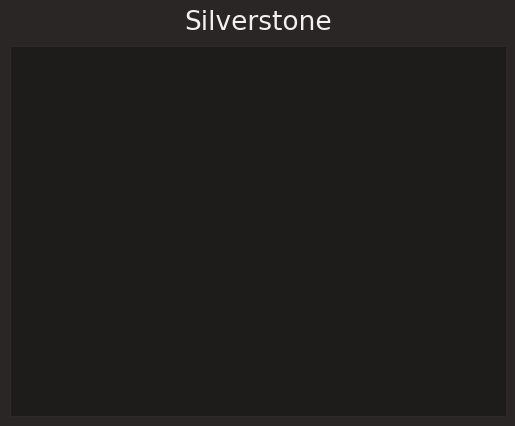

In [39]:
plt.title(session.event['Location'])
plt.xticks([])
plt.yticks([])
plt.axis('equal')

# 2. Lap Time Analysis

### 2.1 Driver Laptimes Scatterplot

In [41]:
import seaborn as sns
from matplotlib import pyplot as plt

import fastf1
import fastf1.plotting


# Enable Matplotlib patches for plotting timedelta values and load
# FastF1's dark color scheme
fastf1.plotting.setup_mpl(mpl_timedelta_support=True, color_scheme='fastf1')

In [42]:
race = fastf1.get_session(2023, "Azerbaijan", 'R')
race.load()

core           INFO 	Loading data for Azerbaijan Grand Prix - Race [v3.8.3]
req            INFO 	Using cached data for session_info
req            INFO 	Using cached data for driver_info
req            INFO 	Using cached data for session_status_data
req            INFO 	Using cached data for lap_count
req            INFO 	Using cached data for track_status_data
req            INFO 	Using cached data for _extended_timing_data
req            INFO 	Using cached data for timing_app_data
core           INFO 	Processing timing data...
req            INFO 	Using cached data for car_data
req            INFO 	Using cached data for position_data
req            INFO 	Using cached data for weather_data
req            INFO 	Using cached data for race_control_messages
core           INFO 	Finished loading data for 20 drivers: ['11', '1', '16', '14', '55', '44', '18', '63', '4', '22', '81', '23', '20', '10', '31', '2', '27', '77', '24', '21']


In [43]:
driver_laps = race.laps.pick_drivers("ALO").pick_quicklaps().reset_index()

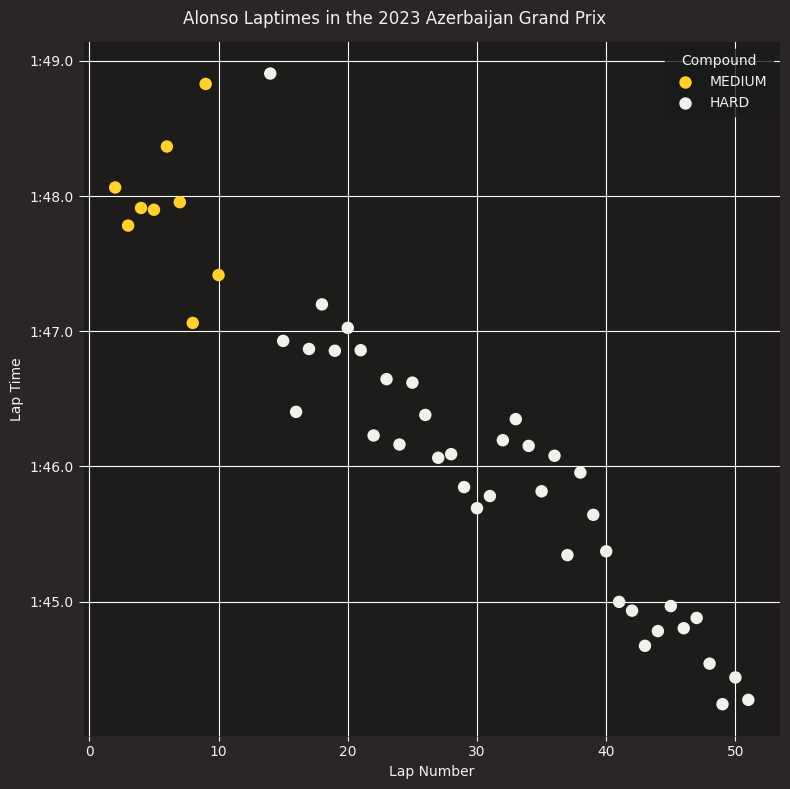

In [47]:
fig, ax = plt.subplots(figsize=(8, 8))

sns.scatterplot(data=driver_laps,
                x="LapNumber",
                y="LapTime",
                ax=ax,
                hue="Compound",
                palette=fastf1.plotting.get_compound_mapping(session=race),
                s=80,
                linewidth=0,
                legend='auto')

ax.set_xlabel("Lap Number")
ax.set_ylabel("Lap Time")

# The y-axis increases from bottom to top by default
# Since we are plotting time, it makes sense to invert the axis
ax.invert_yaxis()
plt.suptitle("Alonso Laptimes in the 2023 Azerbaijan Grand Prix")

# Turn on major grid lines
plt.grid(color='w', which='major', axis='both')
sns.despine(left=True, bottom=True)

plt.tight_layout()
plt.show()

In [48]:
#conveerting from matplotlib to plotly
from plotly.tools import mpl_to_plotly
import plotly.graph_objects as go

plotly_fig = mpl_to_plotly(fig)
import plotly.io as pio
pio.show(plotly_fig)

/Users/aksha/Documents/C/CoDeS/AI_Engineer/FastF1/venv/lib/python3.12/site-packages/plotly/matplotlylib/renderer.py:556: UserWarning: I found a path object that I don't think is part of a bar chart. Ignoring.
  warnings.warn(


### 2.2 Driver Laptimes Distribution Visualization

In [49]:
import fastf1.plotting


# Enable Matplotlib patches for plotting timedelta values and load
# FastF1's dark color scheme
fastf1.plotting.setup_mpl(mpl_timedelta_support=True, color_scheme='fastf1')

In [50]:
race = fastf1.get_session(2023, "Azerbaijan", 'R')
race.load()

point_finishers = race.drivers[:10]
print(point_finishers)
driver_laps = race.laps.pick_drivers(point_finishers).pick_quicklaps()
driver_laps = driver_laps.reset_index()

core           INFO 	Loading data for Azerbaijan Grand Prix - Race [v3.8.3]
req            INFO 	Using cached data for session_info
req            INFO 	Using cached data for driver_info
req            INFO 	Using cached data for session_status_data
req            INFO 	Using cached data for lap_count
req            INFO 	Using cached data for track_status_data
req            INFO 	Using cached data for _extended_timing_data
req            INFO 	Using cached data for timing_app_data
core           INFO 	Processing timing data...
req            INFO 	Using cached data for car_data
req            INFO 	Using cached data for position_data
req            INFO 	Using cached data for weather_data
req            INFO 	Using cached data for race_control_messages
core           INFO 	Finished loading data for 20 drivers: ['11', '1', '16', '14', '55', '44', '18', '63', '4', '22', '81', '23', '20', '10', '31', '2', '27', '77', '24', '21']


['11', '1', '16', '14', '55', '44', '18', '63', '4', '22']


In [51]:
finishing_order = [race.get_driver(i)["Abbreviation"] for i in point_finishers]
print(finishing_order)

['PER', 'VER', 'LEC', 'ALO', 'SAI', 'HAM', 'STR', 'RUS', 'NOR', 'TSU']


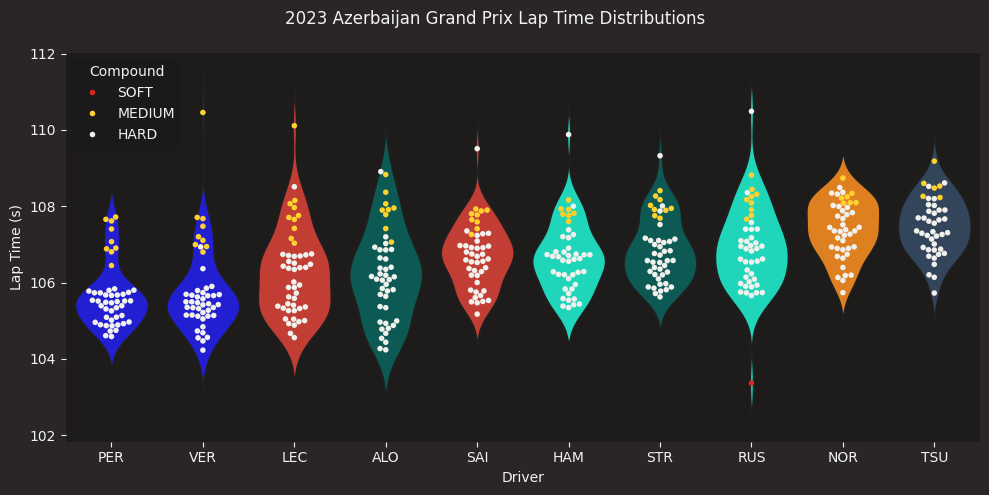

In [53]:
# create the figure
fig, ax = plt.subplots(figsize=(10, 5))

# Seaborn doesn't have proper timedelta support,
# so we have to convert timedelta to float (in seconds)
driver_laps["LapTime(s)"] = driver_laps["LapTime"].dt.total_seconds()

sns.violinplot(data=driver_laps,
               x="Driver",
               y="LapTime(s)",
               hue="Driver",
               inner=None,
               density_norm="area",
               order=finishing_order,
               palette=fastf1.plotting.get_driver_color_mapping(session=race)
               )

sns.swarmplot(data=driver_laps,
              x="Driver",
              y="LapTime(s)",
              order=finishing_order,
              hue="Compound",
              palette=fastf1.plotting.get_compound_mapping(session=race),
              hue_order=["SOFT", "MEDIUM", "HARD"],
              linewidth=0,
              size=4,
              )

ax.set_xlabel("Driver")
ax.set_ylabel("Lap Time (s)")
plt.suptitle("2023 Azerbaijan Grand Prix Lap Time Distributions")
sns.despine(left=True, bottom=True)

plt.tight_layout()
plt.show()

In [54]:
#conveerting from matplotlib to plotly
from plotly.tools import mpl_to_plotly
import plotly.graph_objects as go

plotly_fig = mpl_to_plotly(fig)
import plotly.io as pio
pio.show(plotly_fig)

/Users/aksha/Documents/C/CoDeS/AI_Engineer/FastF1/venv/lib/python3.12/site-packages/plotly/matplotlylib/renderer.py:518: UserWarning: Dang! That path collection is out of this world. I totally don't know what to do with it yet! Plotly can only import path collections linked to 'data' coordinates
  warnings.warn(
/Users/aksha/Documents/C/CoDeS/AI_Engineer/FastF1/venv/lib/python3.12/site-packages/plotly/matplotlylib/renderer.py:556: UserWarning: I found a path object that I don't think is part of a bar chart. Ignoring.
  warnings.warn(


In [1]:
import fastf1

# Example: 2024 Saudi Arabian GP, Free Practice 1
session = fastf1.get_session(2024, 'Saudi Arabian Grand Prix', 'FP1')
session.load()


req         WARNING 	DEFAULT CACHE ENABLED! (163.41 MB) /Users/aksha/Library/Caches/fastf1
core           INFO 	Loading data for Saudi Arabian Grand Prix - Practice 1 [v3.8.3]
req            INFO 	No cached data found for session_info. Loading data...
_api           INFO 	Fetching session info data...
req            INFO 	Data has been written to cache!
req            INFO 	No cached data found for driver_info. Loading data...
_api           INFO 	Fetching driver list...
req            INFO 	Data has been written to cache!
req            INFO 	No cached data found for session_status_data. Loading data...
_api           INFO 	Fetching session status data...
req            INFO 	Data has been written to cache!
req            INFO 	No cached data found for track_status_data. Loading data...
_api           INFO 	Fetching track status data...
req            INFO 	Data has been written to cache!
req            INFO 	No cached data found for _extended_timing_data. Loading data...
_api        

In [2]:
from matplotlib import pyplot as plt

import fastf1
import fastf1.plotting

session = fastf1.get_session(2022, "Hungary", 'R')
session.load()
laps = session.laps

drivers = session.drivers
print(drivers)

core           INFO 	Loading data for Hungarian Grand Prix - Race [v3.8.3]
req            INFO 	No cached data found for session_info. Loading data...
_api           INFO 	Fetching session info data...
req            INFO 	Data has been written to cache!
req            INFO 	No cached data found for driver_info. Loading data...
_api           INFO 	Fetching driver list...
req            INFO 	Data has been written to cache!
req            INFO 	No cached data found for session_status_data. Loading data...
_api           INFO 	Fetching session status data...
req            INFO 	Data has been written to cache!
req            INFO 	No cached data found for lap_count. Loading data...
_api           INFO 	Fetching lap count data...
req            INFO 	Data has been written to cache!
req            INFO 	No cached data found for track_status_data. Loading data...
_api           INFO 	Fetching track status data...
req            INFO 	Data has been written to cache!
req            INFO 	No 

['1', '44', '63', '55', '11', '16', '4', '14', '31', '5', '18', '10', '24', '47', '3', '20', '23', '6', '22', '77']


In [3]:
drivers = [session.get_driver(driver)["Abbreviation"] for driver in drivers]
print(drivers)

['VER', 'HAM', 'RUS', 'SAI', 'PER', 'LEC', 'NOR', 'ALO', 'OCO', 'VET', 'STR', 'GAS', 'ZHO', 'MSC', 'RIC', 'MAG', 'ALB', 'LAT', 'TSU', 'BOT']


In [4]:
stints = laps[["Driver", "Stint", "Compound", "LapNumber"]]
stints = stints.groupby(["Driver", "Stint", "Compound"])
stints = stints.count().reset_index()

stints = stints.rename(columns={"LapNumber": "StintLength"})
print(stints)

   Driver  Stint Compound  StintLength
0     ALB    1.0     SOFT            2
1     ALB    2.0   MEDIUM           19
2     ALB    3.0   MEDIUM           19
3     ALB    4.0     SOFT           29
4     ALO    1.0   MEDIUM           21
..    ...    ...      ...          ...
57    VET    2.0   MEDIUM           31
58    VET    3.0   MEDIUM           23
59    ZHO    1.0   MEDIUM           27
60    ZHO    2.0     HARD           24
61    ZHO    3.0     SOFT           18

[62 rows x 4 columns]


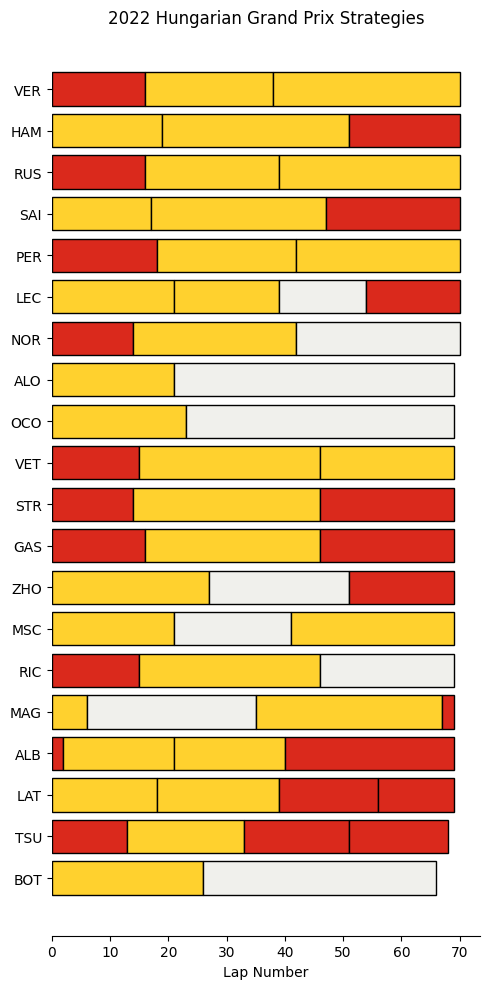

In [8]:
fig, ax = plt.subplots(figsize=(5, 10))



for driver in drivers:
    driver_stints = stints.loc[stints["Driver"] == driver]

    previous_stint_end = 0
    for idx, row in driver_stints.iterrows():
        # each row contains the compound name and stint length
        # we can use these information to draw horizontal bars
        compound_color = fastf1.plotting.get_compound_color(row["Compound"],
                                                            session=session)
        plt.barh(
            y=driver,
            width=row["StintLength"],
            left=previous_stint_end,
            color=compound_color,
            edgecolor="black",
            fill=True
        )

        previous_stint_end += row["StintLength"]

plt.title("2022 Hungarian Grand Prix Strategies")
plt.xlabel("Lap Number")
plt.grid(False)
# invert the y-axis so drivers that finish higher are closer to the top
ax.invert_yaxis()

ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['left'].set_visible(False)

plt.tight_layout()
plt.show()


In [9]:
import plotly.graph_objects as go

def plot_strategy_plotly(stints, drivers, session_name="Race Strategies"):
    fig = go.Figure()

    for driver in drivers:
        driver_stints = stints.loc[stints["Driver"] == driver]

        previous_stint_end = 0
        for _, row in driver_stints.iterrows():
            # Use FastF1’s compound color mapping
            compound_color = fastf1.plotting.get_compound_color(row["Compound"], session=session_name)

            fig.add_trace(go.Bar(
                x=[row["StintLength"]],
                y=[driver],
                orientation='h',
                marker=dict(color=compound_color, line=dict(color="black", width=1)),
                base=previous_stint_end,
                name=row["Compound"],
                hovertemplate=(
                    f"Driver: {driver}<br>"
                    f"Compound: {row['Compound']}<br>"
                    f"Stint Length: {row['StintLength']} laps<extra></extra>"
                ),
                showlegend=False
            ))

            previous_stint_end += row["StintLength"]

    fig.update_layout(
        title="Tyre Strategies",
        xaxis_title="Lap Number",
        yaxis=dict(autorange="reversed"),  # invert y-axis
        bargap=0.2,
        height=600,
        width=900,
        plot_bgcolor="white"
    )

    return fig
